# Alignment in Depth

A tilt series must be aligned before it is reconstructed: the specimen drifts between
projections, and the tilt axis is rarely exactly where the reconstruction assumes it is (centred,
and parallel to the image x-axis). This notebook measures each of ETSpy's alignment tools against
a simulated tilt series whose misalignment is known exactly. You will learn:

* How to score an alignment, and which parts of it cannot be determined from the data
* The four registration methods of `stack_register`, and Fourier against spline interpolation of
  the shifts
* Finding the tilt axis with `tilt_align`, and checking it with `test_align`
* Repairing a single jump in a series with `manual_align`
* Applying the alignment of one signal to another acquired at the same time, with `align_other`

For the highest accuracy, projection matching refines the alignment further; it has its own
[notebook](projection_matching_demo.ipynb).

## Imports

In [1]:
%matplotlib inline

import time

import matplotlib.pyplot as plt
import numpy as np
import hyperspy.api as hs

import etspy.api as tomo
from etspy import align
from etspy import simulation as sim

tomo.set_log_level("WARNING")

## A Test Series with Known Misalignment

`create_alignment_test_series` simulates a tilt series of a phantom with features that are sharp
in every direction (particles, boxes, plates and rods on a thin support), then misaligns it with
random jitter plus a slow drift, and rotates the tilt axis. It returns:

* `misaligned`: the series to align, here with shot noise (`dose` counts per pixel in vacuum)
* `aligned`: the ideal series, without misalignment or noise
* `shifts`: the (Y, X) shifts that correct the misalignment of each projection, in pixels
* `tilt_axis`: the in-plane rotation (degrees) that corrects the tilt axis direction

The series covers 180\u00b0 in 2\u00b0 steps, and the tilt axis is rotated by 1\u00b0. Like
real data, the projections have a background (the vacuum level, here 0.2), which is removed with
`remove_background` before anything else; a background left in the data reconstructs as a ring
of wrong intensity.

In [2]:
series = sim.create_alignment_test_series(
    shape=(160, 160),
    tilts=np.arange(-90, 90, 2.0),
    max_shift=3.0,
    drift=2.0,
    tilt_axis=1.0,
    blur=0.5,
    dose=200,
    seed=2,
)
tilts = series.misaligned.tilts.data.squeeze()
stack = series.misaligned.remove_background()
print(stack)
print(f"true tilt axis rotation: {series.tilt_axis} degrees")
print(f"rms of the true shifts (Y, X): {np.sqrt((series.shifts**2).mean(0)).round(2)} px")

<TomoStack, title: , dimensions: (90|160, 160)>
true tilt axis rotation: 1.0 degrees
rms of the true shifts (Y, X): [2.32 1.86] px


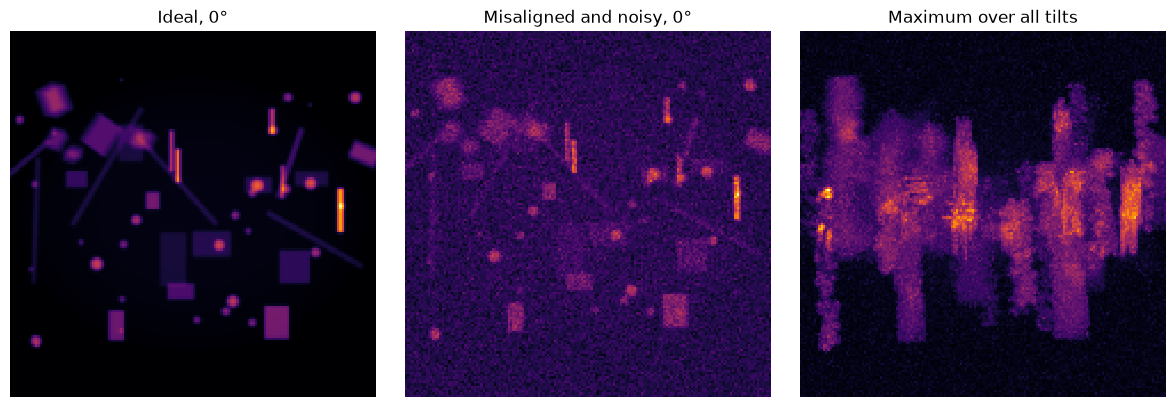

In [3]:
k = np.argmin(abs(tilts))
hs.plot.plot_images(
    [series.aligned.inav[k], stack.inav[k], stack.max()],
    per_row=3, cmap="inferno", axes_decor="off", colorbar=None,
    label=["Ideal, 0\u00b0", "Misaligned and noisy, 0\u00b0", "Maximum over all tilts"],
)
plt.gcf().set_size_inches(12, 4)
plt.tight_layout()

### Scoring an Alignment

Some parts of the shifts cannot be found from the data, because they leave the reconstruction
unchanged apart from moving it:

* along the tilt axis (X), a shift common to all projections only moves the reconstruction along
  the axis
* perpendicular to the axis (Y), shifts of the form b cos \u03b8 + c sin \u03b8 only move the
  reconstruction within each slice

A Y shift common to all projections is different: it moves the tilt axis, which does change the
reconstruction. But registration cannot find it, because it only compares projections with each
other; finding the axis is the job of `tilt_align` (below). So the errors of the registration
methods are measured after removing all three parts. In ETSpy, the shifts found
are stored in the `shifts` attribute of the aligned stack, in (Y, X) order like the true shifts.

In [4]:
def shift_errors(found, truth=series.shifts, tilts=tilts):
    """RMS error (px) of (Y, X) shifts, without the parts that cannot be determined."""
    theta = np.deg2rad(tilts)
    basis = np.array([np.ones_like(theta), np.cos(theta), np.sin(theta)]).T
    dy = found[:, 0] - truth[:, 0]
    dy = dy - basis @ np.linalg.lstsq(basis, dy, rcond=None)[0]
    dx = found[:, 1] - truth[:, 1]
    dx = dx - np.median(dx)
    return np.sqrt(np.mean(dy**2)), np.sqrt(np.mean(dx**2))


print("no alignment: Y %.2f px, X %.2f px" % shift_errors(np.zeros_like(series.shifts)))

no alignment: Y 1.87 px, X 1.84 px


## Registration Methods

`stack_register` aligns each projection with its neighbour, working outwards from the central one
(or from `start`):

| Method | How it works | Suited to |
|---|---|---|
| `"PC"` | Phase correlation of neighbouring projections | General use; fast |
| `"StackReg"` | Intensity-based registration (pystackreg) | General use; robust |
| `"COM"` | Centre of mass tracking perpendicular to the tilt axis | Isolated objects that stay in the field of view |
| `"COM-CL"` | Centre of mass perpendicular to the axis, common line along it | Isolated objects, such as needles and particles |

Registering neighbours lets small errors accumulate along the series, and it cannot see a
misplaced tilt axis: those are the job of `tilt_align` and projection matching.

In [5]:
results = {}
for method in ["PC", "StackReg", "COM", "COM-CL"]:
    t0 = time.perf_counter()
    reg = stack.stack_register(method)
    results[method] = (*shift_errors(reg.shifts.data), time.perf_counter() - t0)

print(f"{'method':9s} {'Y error (px)':>12s} {'X error (px)':>12s} {'time (s)':>9s}")
for method, (ey, ex, sec) in results.items():
    print(f"{method:9s} {ey:12.2f} {ex:12.2f} {sec:9.1f}")

method    Y error (px) X error (px)  time (s)
PC                0.80         0.34       1.1
StackReg          0.47         0.14       1.9
COM               1.36         0.30       0.6
COM-CL            0.76         0.06       0.8


On this phantom, StackReg is the most accurate perpendicular to the tilt axis (Y), and the common
line of `COM-CL` is the most accurate along it (X). Centre of mass alone is the least accurate in
Y here: the centre-of-mass methods assume that all of the mass stays in view at every tilt, and
the support film of this phantom extends past the edges of the field of view. On a needle or an
isolated particle they work well, and they need no common features between neighbouring
projections. They also need the background removed: with the vacuum level left in, the X error of
`COM-CL` on this series is about 1.8 pixels instead of 0.06.

### Fourier or Spline Interpolation of the Shifts

The shifts are applied by Fourier interpolation by default (`shift_type="fourier"`), or by cubic
spline interpolation (`"interp"`). Both are accurate to a small fraction of a pixel. To compare
them, apply the true shifts to a noise-free copy of the series both ways, and compare the result
with the ideal series. On this test the two are within about 10% of each other; Fourier shifts
can ring at sharp edges that cross the image border, spline shifts slightly smooth the finest
detail. `align.apply_shifts` applies a given set of shifts to a stack:

In [6]:
clean = sim.create_alignment_test_series(
    shape=(160, 160), tilts=np.arange(-90, 90, 2.0), max_shift=3.0, drift=2.0,
    tilt_axis=0.0, blur=0.5, dose=None, seed=2,
)
inner = (slice(None), slice(20, -20), slice(20, -20))   # away from the edges
for method in ["fourier", "interp"]:
    shifted = align.apply_shifts(clean.misaligned, clean.shifts, method=method)
    diff = shifted.data[inner] - clean.aligned.data[inner]
    print(f"{method:8s} difference from the ideal series: "
          f"{np.linalg.norm(diff) / np.linalg.norm(clean.aligned.data[inner]):.4f}")

fourier  difference from the ideal series: 0.0159


interp   difference from the ideal series: 0.0146


## Tilt Axis Alignment

After registration, the projections are aligned with each other, but the tilt axis may still be
off-centre and rotated. `tilt_align` finds it:

* `"CoM"`: for slices spread along the axis, the centre of mass of each slice is fit to the path
  expected for rotation about an axis; a line through the axis positions gives the shift and the
  rotation. It needs the mass to stay in view at all tilts
* `"MaxImage"`: the axis direction is found from edges in the maximum image (Sobel filter and Hough
  transform); `also_shift=True` also finds the shift

The rotation found is stored in the `tiltaxis` entry of the `Tomography` metadata, with the same
sign convention as the true value. On this phantom, which has no long edges along the tilt axis,
`MaxImage` underestimates the rotation, while `CoM` comes within about 0.1\u00b0:

In [7]:
reg = stack.stack_register("StackReg")
for method in ["CoM", "MaxImage"]:
    ali = reg.tilt_align(method)
    found = float(ali.metadata.Tomography.tiltaxis)
    print(f"{method:8s} tilt axis {found:6.2f} degrees (true {series.tilt_axis})")
ali = reg.tilt_align("CoM")

CoM      tilt axis   1.10 degrees (true 1.0)


MaxImage tilt axis   0.36 degrees (true 1.0)


### Checking the Alignment with `test_align`

`test_align` reconstructs a few slices quickly. A correct tilt axis gives compact features; an
offset axis gives arcs (a feature traces part of a circle), and a rotated one gives arcs that
change from slice to slice. The optional `tilt_shift` and `tilt_rotation` arguments try a
correction without applying it, which is useful for finding the axis by eye:

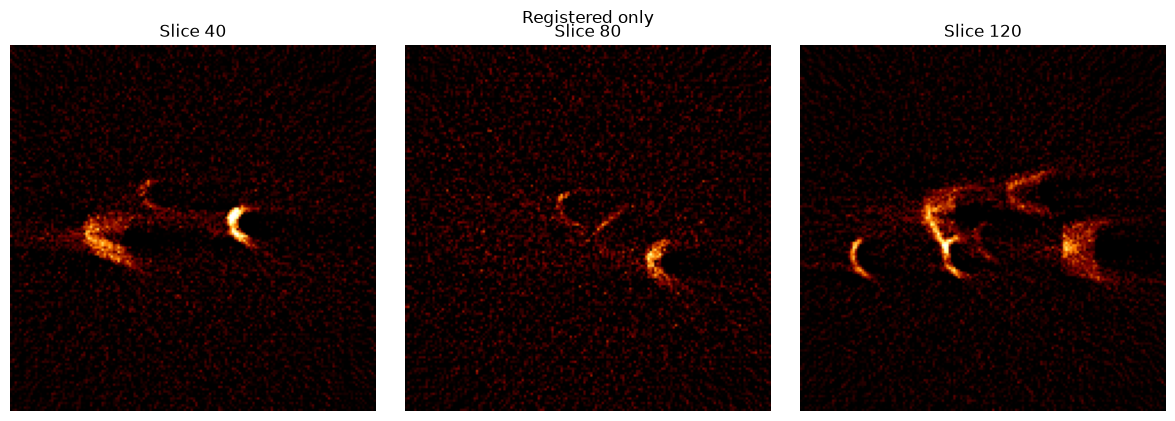

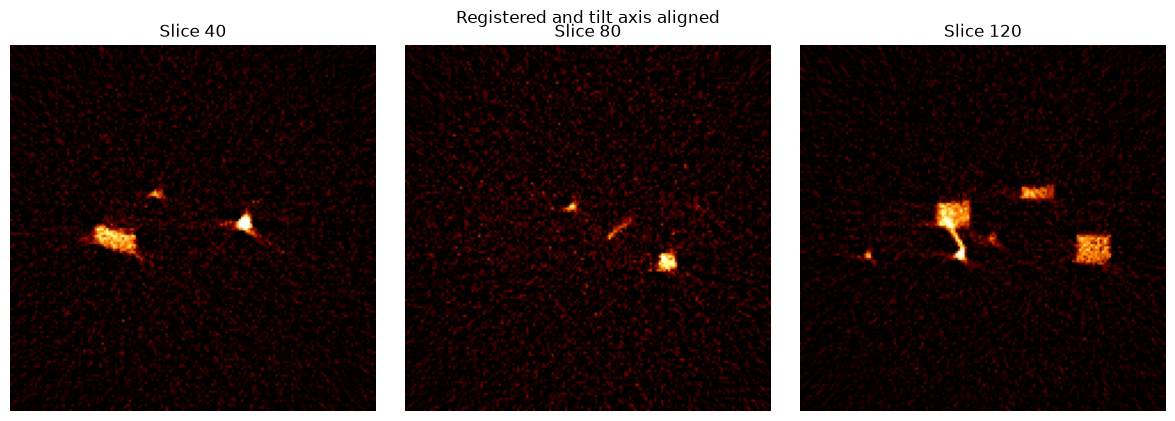

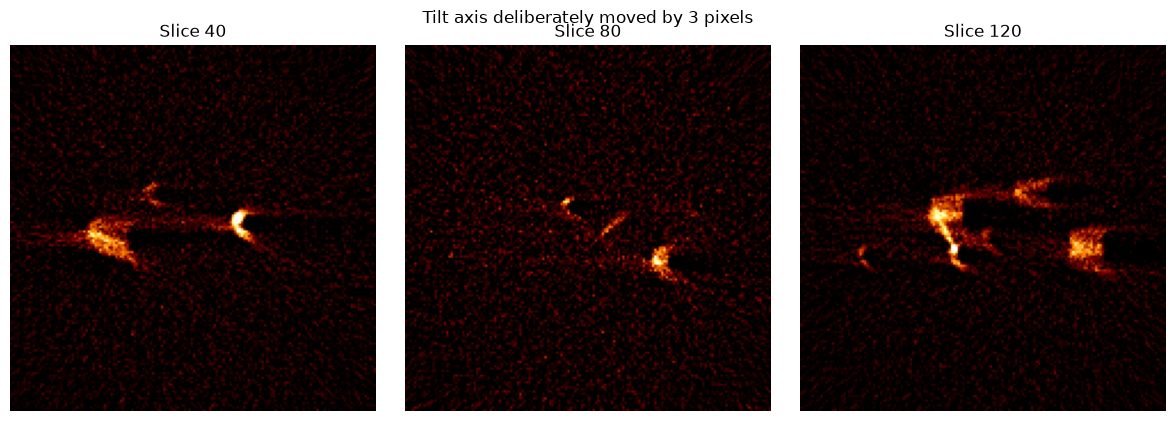

In [8]:
f = reg.test_align(slices=[40, 80, 120])
f.suptitle("Registered only", y=1.04)
f = ali.test_align(slices=[40, 80, 120])
f.suptitle("Registered and tilt axis aligned", y=1.04)
f = ali.test_align(slices=[40, 80, 120], tilt_shift=3)
f.suptitle("Tilt axis deliberately moved by 3 pixels", y=1.04);

## Repairing a Jump with `manual_align`

Sometimes a series contains a sudden jump, for example where the stage was re-centred, and
registration across it fails. `manual_align(nslice, xshift, yshift)` shifts all of the projections
from `nslice` onwards by a whole number of pixels relative to those before it, and crops the stack
to the overlap. Here we add a jump of 10 pixels to the ideal (noise-free) series, and remove it
again; the jump shows as a break in the sinogram:

shape before: (90, 160, 160)  after: (90, 150, 160)


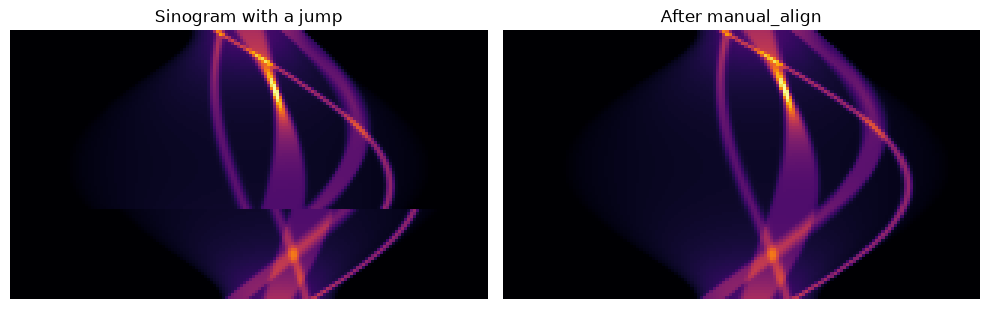

In [9]:
jumped = series.aligned.remove_background()
j = 60
jumped.data[j:] = np.roll(jumped.data[j:], 10, axis=1)         # 10 px jump in Y from projection 60
fixed = jumped.manual_align(j, yshift=-10)

hs.plot.plot_images(
    [jumped.extract_sinogram(80), fixed.extract_sinogram(80)],
    per_row=2, cmap="inferno", axes_decor="off", colorbar=None,
    label=["Sinogram with a jump", "After manual_align"],
)
plt.gcf().set_size_inches(10, 4)
plt.tight_layout()
print("shape before:", jumped.data.shape, " after:", fixed.data.shape)

## Aligning a Second Signal with `align_other`

Many tilt series record several signals at once, for example HAADF and bright-field STEM images,
or a spectrum image alongside an image. The signals share the same specimen motion, so the
alignment found on the best one (here the HAADF-like series) can be applied to the others with
`align_other`: it applies the shifts, the tilt axis shift and the rotation in the same order.
The images below show the minimum over all projections, which is sharp only when the series is
aligned.

As a second signal we use a bright-field-like image of the same series, in which the contrast is
reversed and not proportional to the density:

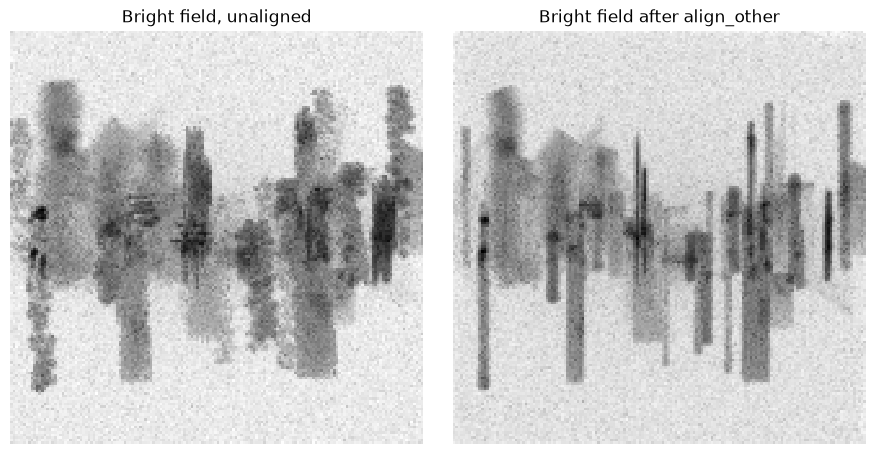

In [10]:
bright_field = stack.deepcopy()
bright_field.data = np.exp(-2 * stack.data / stack.data.max())

bf_aligned = ali.align_other(bright_field)

hs.plot.plot_images(
    [bright_field.min(), bf_aligned.min()],
    per_row=2, cmap="gray", axes_decor="off", colorbar=None,
    label=["Bright field, unaligned", "Bright field after align_other"],
)
plt.gcf().set_size_inches(9, 4.5)
plt.tight_layout()

## Summary

* Register with `"StackReg"` or `"PC"` for general specimens, `"COM-CL"` for isolated objects that
  stay in view
* Then find the tilt axis with `tilt_align("CoM")` (or `"MaxImage"`), and check with `test_align`
* For sub-pixel accuracy, refine with [projection matching](projection_matching_demo.ipynb)
* Align the best signal, and apply the result to the others with `align_other`